In [1]:
import pandas as pd

In [2]:
region_demand=pd.read_csv(r'C:\Users\Loq\OneDrive\Desktop\project\region_demand_dataset_5000.csv')
region_demand

,State,City,Region,Product_Category,Demand_Score,Demand_Level,Units_Sold,Average_Price,Month,Year
0,Delhi,Gurugram,North,Clothing,6,Low,40,30778,6,2024
1,Gujarat,Mumbai,West,Grocery,43,Medium,433,28952,10,2024
2,West Bengal,Lucknow,East,Clothing,3,Low,490,19530,6,2023
3,Haryana,Chandigarh,North,Clothing,78,High,341,48865,12,2022
4,Telangana,Delhi,South,Furniture,65,Medium,148,48621,9,2022
...,...,...,...,...,...,...,...,...,...,...
4995,Gujarat,Ahmedabad,West,Electronics,99,High,456,49525,3,2024
4996,Telangana,Kochi,South,Grocery,57,Medium,331,4371,11,2023
4997,Gujarat,Chennai,West,Beauty,41,Medium,243,21200,11,2024
4998,Karnataka,Lucknow,South,Beauty,54,Medium,364,40796,11,2024


In [3]:
region_demand.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   State             5000 non-null   object
 1   City              5000 non-null   object
 2   Region            5000 non-null   object
 3   Product_Category  5000 non-null   object
 4   Demand_Score      5000 non-null   int64 
 5   Demand_Level      5000 non-null   object
 6   Units_Sold        5000 non-null   int64 
 7   Average_Price     5000 non-null   int64 
 8   Month             5000 non-null   int64 
 9   Year              5000 non-null   int64 
dtypes: int64(5), object(5)
memory usage: 390.8+ KB


In [4]:
region_demand.isnull().sum()

State               0
City                0
Region              0
Product_Category    0
Demand_Score        0
Demand_Level        0
Units_Sold          0
Average_Price       0
Month               0
Year                0
dtype: int64

In [5]:
region_demand.columns

Index(['State', 'City', 'Region', 'Product_Category', 'Demand_Score',
       'Demand_Level', 'Units_Sold', 'Average_Price', 'Month', 'Year'],
      dtype='object')

In [6]:
import numpy as np

In [7]:
state=np.unique(region_demand['State'])
city=np.unique(region_demand['City'])
print(state)
print(city)

['Delhi' 'Gujarat' 'Haryana' 'Karnataka' 'Kerala' 'Maharashtra' 'Punjab'
 'Rajasthan' 'Tamil Nadu' 'Telangana' 'Uttar Pradesh' 'West Bengal']
['Ahmedabad' 'Bengaluru' 'Chandigarh' 'Chennai' 'Delhi' 'Gurugram'
 'Hyderabad' 'Jaipur' 'Kochi' 'Kolkata' 'Lucknow' 'Mumbai']


In [8]:
region_demand['City']=region_demand['City'].replace({
    'Bengaluru':'Bangalore'
})

In [9]:
region_demand.columns = region_demand.columns.str.strip().str.title()

In [10]:
region_demand.drop_duplicates(inplace=True)

In [11]:
region_demand

,State,City,Region,Product_Category,Demand_Score,Demand_Level,Units_Sold,Average_Price,Month,Year
0,Delhi,Gurugram,North,Clothing,6,Low,40,30778,6,2024
1,Gujarat,Mumbai,West,Grocery,43,Medium,433,28952,10,2024
2,West Bengal,Lucknow,East,Clothing,3,Low,490,19530,6,2023
3,Haryana,Chandigarh,North,Clothing,78,High,341,48865,12,2022
4,Telangana,Delhi,South,Furniture,65,Medium,148,48621,9,2022
...,...,...,...,...,...,...,...,...,...,...
4995,Gujarat,Ahmedabad,West,Electronics,99,High,456,49525,3,2024
4996,Telangana,Kochi,South,Grocery,57,Medium,331,4371,11,2023
4997,Gujarat,Chennai,West,Beauty,41,Medium,243,21200,11,2024
4998,Karnataka,Lucknow,South,Beauty,54,Medium,364,40796,11,2024


In [12]:
region_demand.to_csv("cleaned_region_demand.csv",index=False)

In [13]:
import matplotlib.pyplot as plt

<BarContainer object of 4 artists>

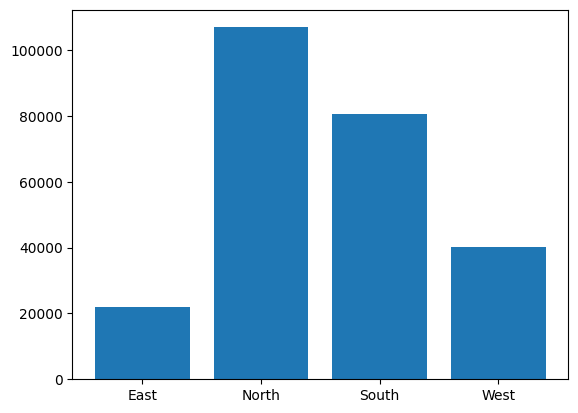

In [14]:
rd=region_demand.groupby('Region')['Demand_Score'].sum()
plt.bar(rd.index,rd.values)

In [15]:
import seaborn as sns

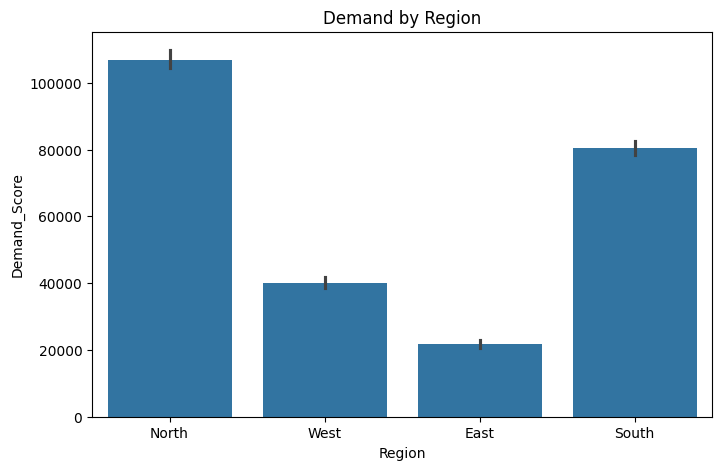

In [17]:
plt.figure(figsize=(8,5))

sns.barplot(x='Region', y='Demand_Score', data=region_demand, estimator=sum)

plt.title("Demand by Region")
plt.show()

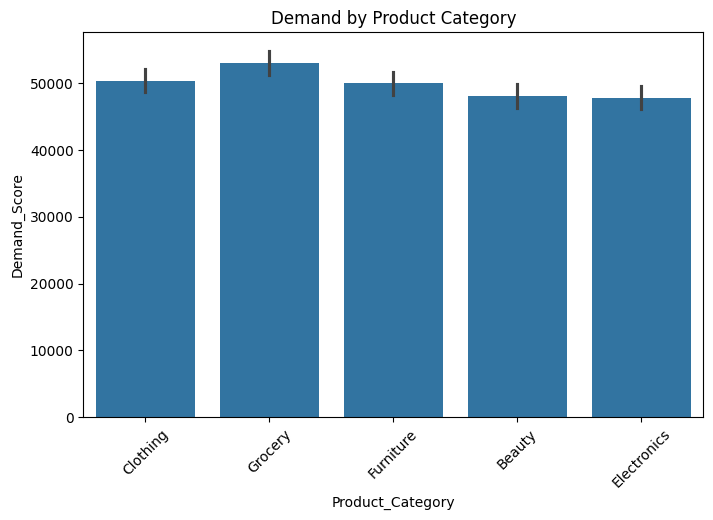

In [18]:
plt.figure(figsize=(8,5))

sns.barplot(x='Product_Category', y='Demand_Score', data=region_demand, estimator=sum)

plt.title("Demand by Product Category")
plt.xticks(rotation=45)
plt.show()

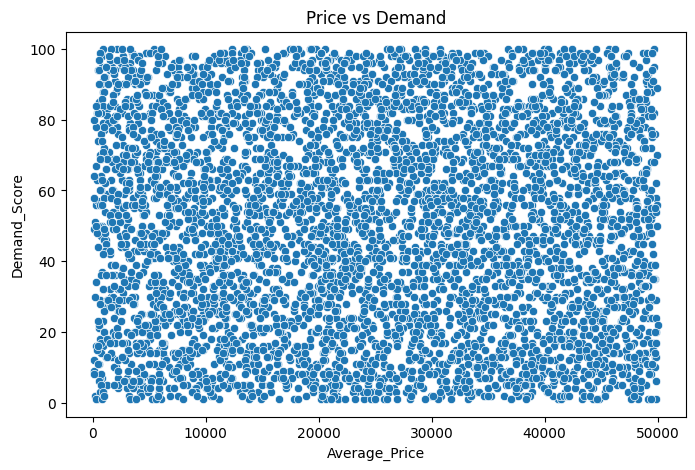

In [20]:
plt.figure(figsize=(8,5))

sns.scatterplot(x='Average_Price', y='Demand_Score', data=region_demand)

plt.title("Price vs Demand")
plt.show()

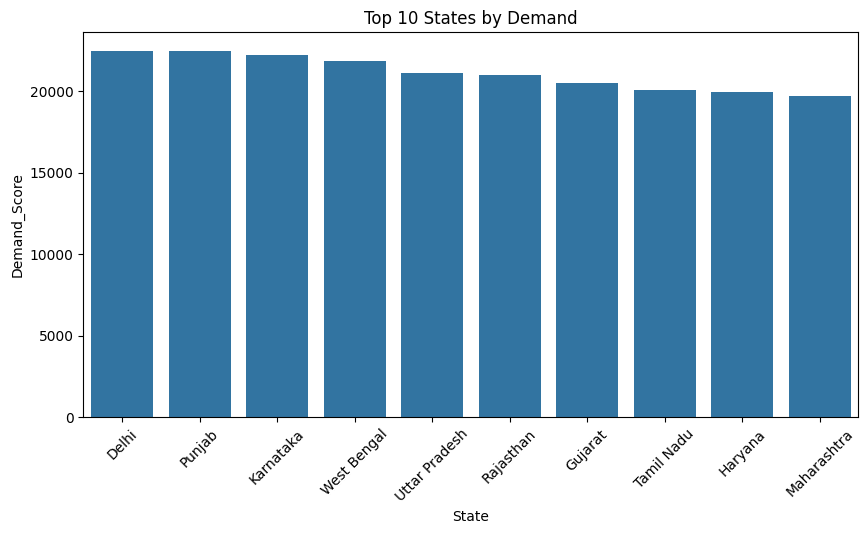

In [21]:
top_states = region_demand.groupby('State')['Demand_Score'].sum().nlargest(10).reset_index()

plt.figure(figsize=(10,5))

sns.barplot(x='State', y='Demand_Score', data=top_states)

plt.title("Top 10 States by Demand")
plt.xticks(rotation=45)
plt.show()

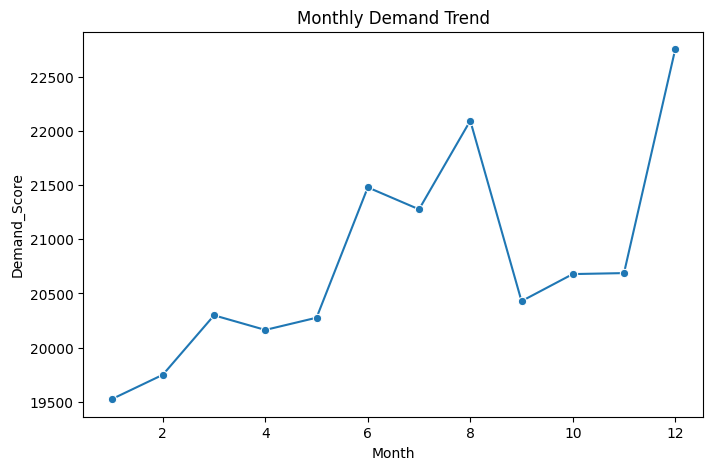

In [22]:
monthly = region_demand.groupby('Month')['Demand_Score'].sum().reset_index()

plt.figure(figsize=(8,5))

sns.lineplot(x='Month', y='Demand_Score', data=monthly, marker='o')

plt.title("Monthly Demand Trend")
plt.show()